In [1]:

import os
import json
import time
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.kernel_approximation import Nystroem

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = [
    p for p in INPUT_DIR.rglob("metadata.json")
    if (p.parent / "X_train_scaled.npy").exists()
]

if not metadata_files:
    raise FileNotFoundError(
        "Processed dataset not found. "
        "Please add Notebook 00 output as input."
    )

DATA_DIR = metadata_files[0].parent

print("Dataset directory:", DATA_DIR)

print("\nAvailable files:")
for file in sorted(DATA_DIR.iterdir()):
    print(file.name)


Dataset directory: /kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]
classes = np.unique(y_train)

print("Dataset loaded successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("Classes:", class_names)
print("Number of Classes:", len(classes))


Dataset loaded successfully!
Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear"
    },
    "Polynomial": {
        "kernel": "poly",
        "degree": 3,
        "coef0": 0
    },
    "RBF": {
        "kernel": "rbf"
    },
    "Sigmoid": {
        "kernel": "sigmoid",
        "coef0": 0
    }
}

MBGD_CONFIG = {
    "learning_rate": 0.01,
    "epochs": 100,
    "batch_size": 64,
    "regularization": 0.001,
    "n_components": 300
}

print("Mini-Batch GD Configuration:")
print(MBGD_CONFIG)

print("\nKernels:")
for name, params in KERNELS.items():
    print(name, params)


Mini-Batch GD Configuration:
{'learning_rate': 0.01, 'epochs': 100, 'batch_size': 64, 'regularization': 0.001, 'n_components': 300}

Kernels:
Linear {'kernel': 'linear'}
Polynomial {'kernel': 'poly', 'degree': 3, 'coef0': 0}
RBF {'kernel': 'rbf'}
Sigmoid {'kernel': 'sigmoid', 'coef0': 0}


In [5]:

def train_svm_mbgd(
    X,
    y,
    learning_rate=0.01,
    epochs=100,
    batch_size=64,
    reg_strength=0.001,
    random_state=42
):
    n_samples, n_features = X.shape

    classes = np.unique(y)
    n_classes = len(classes)

    # One-vs-Rest labels
    Y = np.where(
        y[:, None] == classes[None, :],
        1.0,
        -1.0
    )

    # Initialize weights
    W = np.zeros((n_features, n_classes))

    loss_history = []

    rng = np.random.default_rng(random_state)

    for epoch in range(epochs):

        # Shuffle samples every epoch
        indices = rng.permutation(n_samples)

        # Process mini-batches
        for start in range(0, n_samples, batch_size):

            batch_indices = indices[
                start:start + batch_size
            ]

            X_batch = X[batch_indices]
            Y_batch = Y[batch_indices]

            # Calculate decision scores
            scores = X_batch @ W

            # Calculate hinge margins
            margins = 1 - Y_batch * scores

            # Active hinge losses
            active = (margins > 0).astype(float)

            # Calculate mini-batch gradient
            gradient = (
                -(X_batch.T @ (Y_batch * active))
                / len(batch_indices)
                + reg_strength * W
            )

            # Update weights
            W -= learning_rate * gradient

        # Calculate full training objective
        scores = X @ W

        margins = 1 - Y * scores

        hinge_loss = np.maximum(0, margins)

        epoch_loss = (
            np.mean(hinge_loss, axis=0).sum()
            + 0.5 * reg_strength * np.sum(W ** 2)
        )

        loss_history.append(epoch_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    return W, loss_history, classes


print("Multiclass SVM with Mini-Batch GD implemented successfully!")


Multiclass SVM with Mini-Batch GD implemented successfully!


In [6]:

mbgd_models = {}
mbgd_results = []

for kernel_name, kernel_params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training Mini-Batch GD with {kernel_name} Kernel")
    print("=" * 60)

    start_time = time.time()

    # Kernel approximation
    feature_map = Nystroem(
        n_components=MBGD_CONFIG["n_components"],
        random_state=RANDOM_STATE,
        gamma=1.0 / X_train.shape[1],
        **kernel_params
    )

    Z_train = feature_map.fit_transform(X_train)
    Z_test = feature_map.transform(X_test)

    # Train using Mini-Batch GD
    W, loss_history, trained_classes = train_svm_mbgd(
        Z_train,
        y_train,
        learning_rate=MBGD_CONFIG["learning_rate"],
        epochs=MBGD_CONFIG["epochs"],
        batch_size=MBGD_CONFIG["batch_size"],
        reg_strength=MBGD_CONFIG["regularization"],
        random_state=RANDOM_STATE
    )

    # Predictions
    test_scores = Z_test @ W

    y_pred = trained_classes[
        np.argmax(test_scores, axis=1)
    ]

    training_time = time.time() - start_time

    # Store model
    mbgd_models[kernel_name] = {
        "feature_map": feature_map,
        "weights": W,
        "classes": trained_classes,
        "loss_history": loss_history
    }

    # Evaluation
    mbgd_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Final Loss": loss_history[-1],
        "Training Time": training_time
    })

    print(f"\n{kernel_name} completed!")
    print(f"Final Loss: {loss_history[-1]:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll Mini-Batch GD experiments completed!")



Training Mini-Batch GD with Linear Kernel
Epoch 10/100 | Loss: 4.3231
Epoch 20/100 | Loss: 3.9571
Epoch 30/100 | Loss: 3.8286
Epoch 40/100 | Loss: 3.7669
Epoch 50/100 | Loss: 3.7279
Epoch 60/100 | Loss: 3.7022
Epoch 70/100 | Loss: 3.6812
Epoch 80/100 | Loss: 3.6661
Epoch 90/100 | Loss: 3.6525
Epoch 100/100 | Loss: 3.6393

Linear completed!
Final Loss: 3.6393
Training Time: 4.27 seconds

Training Mini-Batch GD with Polynomial Kernel
Epoch 10/100 | Loss: 5.0433
Epoch 20/100 | Loss: 4.6555
Epoch 30/100 | Loss: 4.4393
Epoch 40/100 | Loss: 4.2941
Epoch 50/100 | Loss: 4.1856
Epoch 60/100 | Loss: 4.1005
Epoch 70/100 | Loss: 4.0313
Epoch 80/100 | Loss: 3.9735
Epoch 90/100 | Loss: 3.9240
Epoch 100/100 | Loss: 3.8816

Polynomial completed!
Final Loss: 3.8816
Training Time: 4.50 seconds

Training Mini-Batch GD with RBF Kernel
Epoch 10/100 | Loss: 1.5204
Epoch 20/100 | Loss: 1.1427
Epoch 30/100 | Loss: 0.9737
Epoch 40/100 | Loss: 0.8845
Epoch 50/100 | Loss: 0.8300
Epoch 60/100 | Loss: 0.7909
Epoc

In [7]:

mbgd_results_df = pd.DataFrame(mbgd_results)

mbgd_results_df = mbgd_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Mini-Batch Gradient Descent Results")

display(
    mbgd_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Final Loss": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)


Mini-Batch Gradient Descent Results


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,RBF,0.9059,0.9230,0.9163,0.9186,0.9066,0.7037,4.31
1,Sigmoid,0.8656,0.8960,0.8851,0.8817,0.8594,3.1657,4.55
2,Linear,0.8221,0.7958,0.8405,0.8094,0.8208,3.6393,4.27
3,Polynomial,0.7789,0.8435,0.8220,0.7743,0.7235,3.8816,4.50


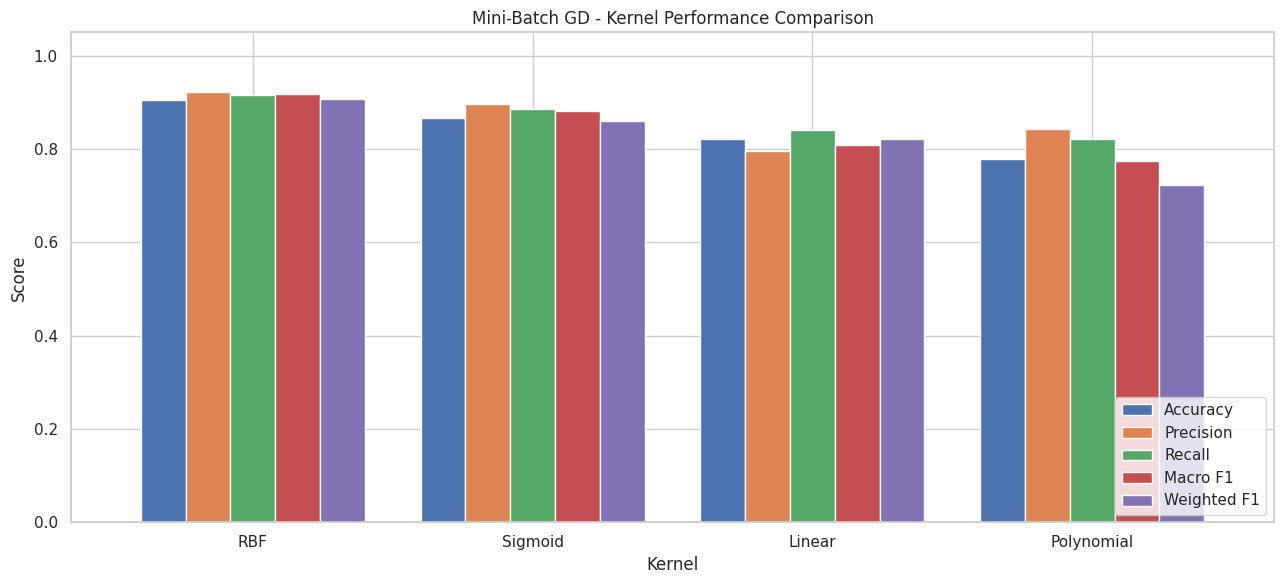

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

mbgd_plot = mbgd_results_df.set_index("Kernel")[metrics]

mbgd_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Mini-Batch GD - Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


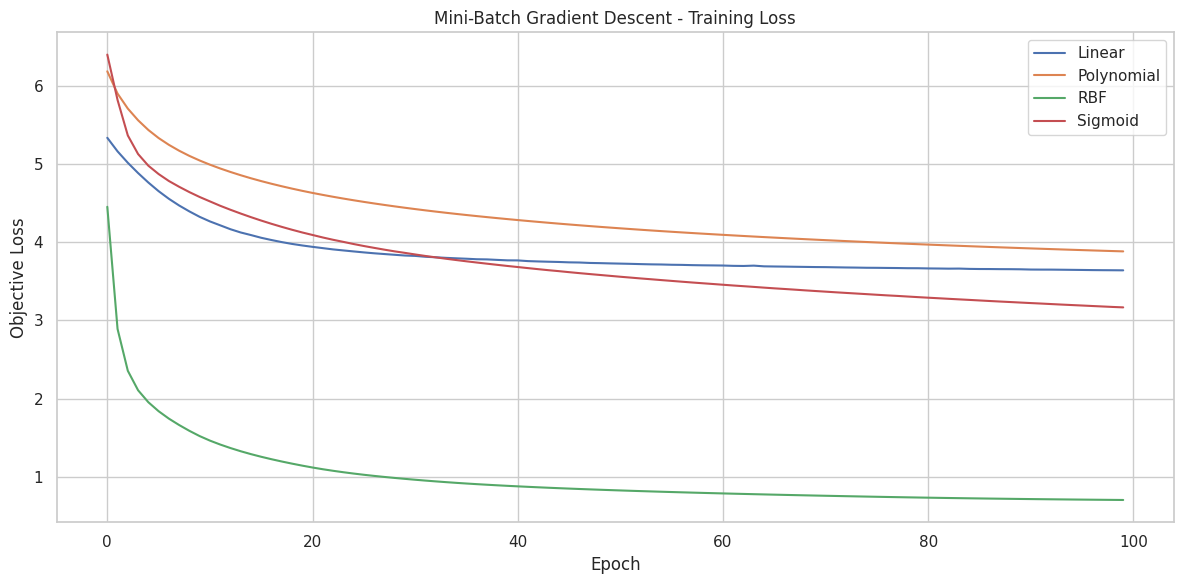

In [9]:

plt.figure(figsize=(12, 6))

for kernel_name, model_data in mbgd_models.items():

    plt.plot(
        model_data["loss_history"],
        label=kernel_name
    )

plt.title("Mini-Batch Gradient Descent - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Objective Loss")

plt.legend()
plt.tight_layout()
plt.show()


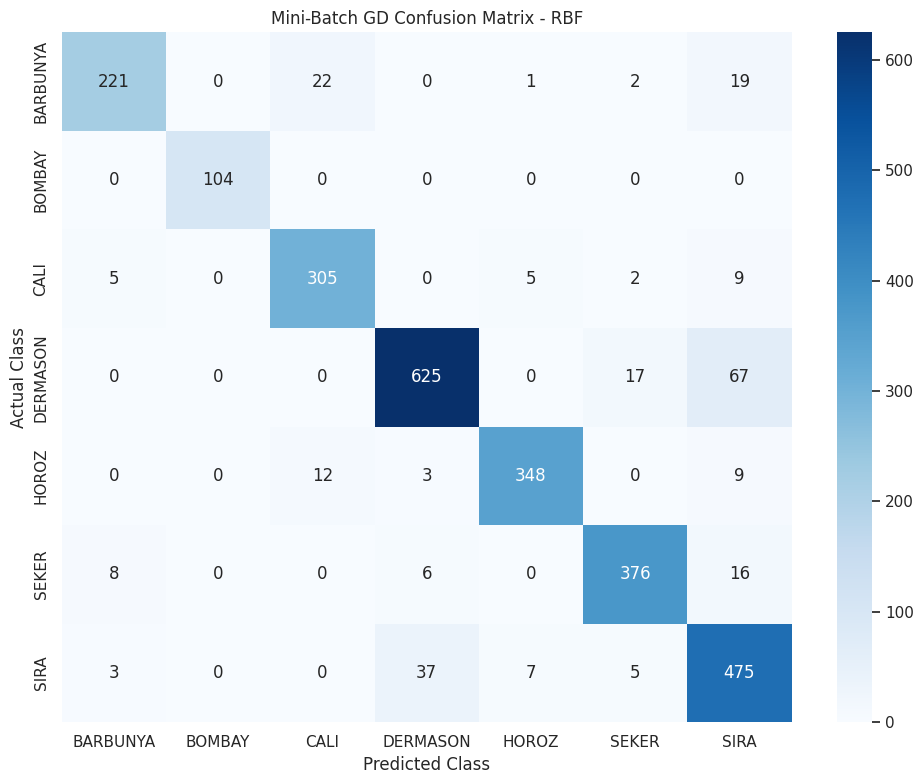

Best Kernel: RBF


In [10]:

best_kernel = mbgd_results_df.iloc[0]["Kernel"]

best_model = mbgd_models[best_kernel]

Z_test_best = best_model["feature_map"].transform(X_test)

y_pred = best_model["classes"][
    np.argmax(
        Z_test_best @ best_model["weights"],
        axis=1
    )
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Mini-Batch GD Confusion Matrix - {best_kernel}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [11]:

print(
    f"Classification Report - Mini-Batch GD with {best_kernel} Kernel"
)

print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - Mini-Batch GD with RBF Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.83      0.88       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.94      0.92       326
    DERMASON       0.93      0.88      0.91       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.93      0.93       406
        SIRA       0.80      0.90      0.85       527

    accuracy                           0.91      2709
   macro avg       0.92      0.92      0.92      2709
weighted avg       0.91      0.91      0.91      2709



In [12]:

OUTPUT_DIR = Path("/kaggle/working/mbgd_results")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
mbgd_results_df.to_csv(
    OUTPUT_DIR / "mbgd_comparison.csv",
    index=False
)

# Save models
joblib.dump(
    mbgd_models,
    OUTPUT_DIR / "mbgd_models.pkl"
)

# Save predictions for all kernels
predictions = {}

for kernel_name, model_data in mbgd_models.items():

    Z_test = model_data["feature_map"].transform(X_test)

    scores = Z_test @ model_data["weights"]

    predictions[kernel_name] = model_data["classes"][
        np.argmax(scores, axis=1)
    ]

predictions_df = pd.DataFrame({
    "Actual": y_test
})

for kernel_name, pred in predictions.items():
    predictions_df[kernel_name] = pred

predictions_df.to_csv(
    OUTPUT_DIR / "mbgd_predictions.csv",
    index=False
)

# Save configuration
config = {
    "optimizer": "Mini-Batch Gradient Descent",
    "learning_rate": MBGD_CONFIG["learning_rate"],
    "epochs": MBGD_CONFIG["epochs"],
    "batch_size": MBGD_CONFIG["batch_size"],
    "regularization": MBGD_CONFIG["regularization"],
    "n_components": MBGD_CONFIG["n_components"],
    "kernels": list(KERNELS.keys()),
    "random_state": RANDOM_STATE,
    "classes": class_names
}

with open(OUTPUT_DIR / "mbgd_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Mini-Batch GD results saved successfully!")

print("\nSaved files:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


Mini-Batch GD results saved successfully!

Saved files:
mbgd_comparison.csv
mbgd_config.json
mbgd_predictions.csv
mbgd_models.pkl
